# ENG2040 assignment 1 - marketplace orders to a model-ready dataset

whole pipeline in one notebook, one section per step. `uv run python run.py` checks the supplied files, rebuilds `data/marketplace.sqlite` from `supplied/data/raw.sql` and runs this top to bottom.

each step writes its outputs to `data/<step>/` plus a `resources.json`. memory is tracked per step by sampling this kernel's rss every 10 ms while the step runs. rss at the start of the step is saved too, since the kernel still holds data from earlier steps.

In [1]:
import json, resource, sqlite3, subprocess, sys, threading, time
from pathlib import Path
import adbc_driver_sqlite.dbapi as adbc
import pandas as pd
import psutil

ROOT = Path.cwd()
DB = ROOT / "data" / "marketplace.sqlite"
con = adbc.connect(f"file:{DB}?mode=ro")  # read only, the db is never modified
q = lambda s: pd.read_sql(s, con, dtype_backend="pyarrow")  # adbc hands results over as arrow columns
proc = psutil.Process()
mb = lambda b: round(b / 1e6, 2)

def track(step):
    # call at the start of a step, call the returned function at the end
    out = ROOT / "data" / step
    out.mkdir(parents=True, exist_ok=True)
    stop, start, peak, t = threading.Event(), proc.memory_info().rss, [proc.memory_info().rss], time.perf_counter()
    def sample():
        while not stop.wait(0.01):
            peak[0] = max(peak[0], proc.memory_info().rss)
    th = threading.Thread(target=sample, daemon=True)
    th.start()
    def done(**extra):
        stop.set(); th.join()
        res = {"step": step, "seconds": round(time.perf_counter() - t, 2), "rss_start_MB": mb(start), "rss_peak_MB": mb(peak[0]),
               "rss_peak_above_start_MB": mb(peak[0] - start),
               "saved_MB": {f.name: mb(f.stat().st_size) for f in sorted(out.iterdir()) if f.name != "resources.json"}, **extra}
        (out / "resources.json").write_text(json.dumps(res, indent=1))
        return res
    return out, done

## step 1 - loading the data

one row per order from the supplied sqlite db. no cleaning in this step. only joining and aggregating, and every count and total gets checked against the db.

in: `data/marketplace.sqlite`

out, in `data/01_load/`:
- `orders.parquet` one row per order
- `items.parquet` one row per order item with its product and seller attributes (for the feature step)
- `checks.csv` every reconciliation check
- `load_comparison.csv` sql vs pandas runtime and memory
- `resources.json` runtime, memory, file sizes

In [2]:
OUT, done = track("01_load")

## tables and keys

- `orders` one row per order, key `order_id`. `customer_id` is the customer record for that one order
- `customers` key `customer_id`. `customer_unique_id` links the same person across orders
- `order_items` one row per purchased item, key `(order_id, order_item_id)`
- `order_payments` one row per payment record, key `(order_id, payment_sequential)`. `payment_value` is in centavos
- `order_reviews` key `(review_id, order_id)`. an order can have several reviews and one review can sit on several orders
- `products`, `sellers` lookups by `product_id`, `seller_id`
- `category_translation` portuguese category -> english

so orders is the grain. items, payments and reviews are one-to-many from an order so they get aggregated to one row per order first. joining them raw would multiply rows (3 items x 2 payments = 6 rows for one order) and double count totals.

the db was loaded with `foreign_keys=OFF` so nothing guarantees the keys actually match. checking that first:

In [3]:
tables = q("select name from sqlite_master where type='table' order by name").name
counts = pd.Series({t: q(f"select count(*) n from {t}").n[0] for t in tables})
print(counts)

links = q('''
select 'orders without a customer row' link, count(*) n from orders o left join customers c on c.customer_id = o.customer_id where c.customer_id is null
union all select 'customers without an order', count(*) from customers c left join orders o on o.customer_id = c.customer_id where o.order_id is null
union all select 'items without an order', count(*) from order_items i left join orders o on o.order_id = i.order_id where o.order_id is null
union all select 'items without a product row', count(*) from order_items i left join products p on p.product_id = i.product_id where p.product_id is null
union all select 'items without a seller row', count(*) from order_items i left join sellers s on s.seller_id = i.seller_id where s.seller_id is null
union all select 'payments without an order', count(*) from order_payments p left join orders o on o.order_id = p.order_id where o.order_id is null
union all select 'reviews without an order', count(*) from order_reviews r left join orders o on o.order_id = r.order_id where o.order_id is null
union all select 'orders with no items', count(*) from orders o where not exists (select 1 from order_items i where i.order_id = o.order_id)
union all select 'orders with no payments', count(*) from orders o where not exists (select 1 from order_payments p where p.order_id = o.order_id)
union all select 'orders with no reviews', count(*) from orders o where not exists (select 1 from order_reviews r where r.order_id = o.order_id)
union all select 'orders with 2+ reviews', count(*) from (select order_id from order_reviews group by order_id having count(*) > 1)
''')
links

category_translation       73
customers               20000
order_items             22662
order_payments          20875
order_reviews           19966
orders                  20000
products                11334
sellers                  2071
dtype: int64


,link,n
0,orders without a customer row,769
1,customers without an order,769
2,items without an order,0
3,items without a product row,910
4,items without a seller row,893
5,payments without an order,0
6,reviews without an order,0
7,orders with no items,142
8,orders with no payments,0
9,orders with no reviews,147


every item, payment and review points at a real order, so nothing gets lost when they roll up to orders. the other direction has gaps (orders with no customer row, no items, items whose product or seller row is missing). keys are all 32 char lowercase hex, so these are real missing rows and not formatting.

hence every join below is a left join from the order (or item) side. a missing customer or product just gives nulls and a flag, the order stays. dropping them is a cleaning decision for step 2, not something loading should do quietly.

the 769 customers with no order cant appear in a one-row-per-order table. they are counted here and left in the db.

## one row per order

aggregation happens inside sqlite. `order_items` and `order_payments` have `order_id` first in their primary key and `order_reviews` has an index on it, so each group by is one ordered pass over an index. only 20000 aggregated rows cross into python instead of ~117k raw ones. they cross through adbc, which hands them to pandas as arrow columns. pythons built in `sqlite3` driver makes one python object per value first, which turned out to be the real memory cost (see the comparison below).

sums ignore nulls in sql, so null counts are kept next to each sum. that way a total can always be traced back. `payment_value` stays in integer centavos here so the totals stay exact. converting to BRL happens in step 2.

In [4]:
ORDERS_SQL = '''
with it as (
  select order_id, count(*) n_items, count(distinct product_id) n_products, count(distinct seller_id) n_sellers,
         sum(price) price_sum, sum(freight_value) freight_sum,
         sum(price is null) n_price_null, sum(freight_value is null) n_freight_null
  from order_items group by order_id),
pay as (
  select order_id, count(*) n_payments, sum(payment_value) payment_sum_centavos, sum(payment_value is null) n_payment_null
  from order_payments group by order_id),
rev as (
  select order_id, count(*) n_reviews from order_reviews group by order_id)
select o.*,
       c.customer_id is not null has_customer, c.customer_unique_id, c.customer_zip_code_prefix, c.customer_city, c.customer_state,
       coalesce(it.n_items, 0) n_items, it.n_products, it.n_sellers, it.price_sum, it.freight_sum, it.n_price_null, it.n_freight_null,
       coalesce(pay.n_payments, 0) n_payments, pay.payment_sum_centavos, pay.n_payment_null,
       coalesce(rev.n_reviews, 0) n_reviews
from orders o
left join customers c on c.customer_id = o.customer_id
left join it on it.order_id = o.order_id
left join pay on pay.order_id = o.order_id
left join rev on rev.order_id = o.order_id
'''
orders = q(ORDERS_SQL)
orders["has_customer"] = orders.has_customer.astype("bool[pyarrow]")
print(orders.shape, orders.memory_usage(deep=True).sum() / 1e6, "MB in memory")
orders.head(3).T

(20000, 24) 7.017963 MB in memory


,0,1,2
order_id,47770eb9100c2d0c44946d9cf07ec65d,76c6e866289321a7c93b82b54852dc33,403b97836b0c04a622354cf531062e5f
customer_id,41ce2a54c0b03bf3443c3d931a367089,f54a9f0e6b351c431402b8461ea51999,7acc63bb81a1111a922c238549b85dde
order_status,delivered,delivered,delivered
order_purchase_timestamp,<NA>,2017-01-23 18:29:09,2018-01-02 19:00:43
order_approved_at,2018-08-08 08:55:23,2017-01-25 02:50:47,2018-01-02 19:09:04
order_delivered_carrier_date,2018-08-08 13:50:00,2017-01-26 14:16:31,2018-01-03 18:19:09
order_delivered_customer_date,2018-08-17 18:06:29,2017-02-02 14:08:10,2018-01-20 01:38:59
order_estimated_delivery_date,2018-09-04 00:00:00,2017-03-06 00:00:00,2018-02-06 00:00:00
has_customer,True,True,False
customer_unique_id,3a653a41f6f9fc3d2a113cf8398680e8,39382392765b6dc74812866ee5ee92a7,<NA>


## one row per item

the feature step needs product and seller attributes, which live at item level. same idea, left joins from the item side. category translation is left out on purpose. category names need normalising first (step 2) or the join silently misses.

In [5]:
ITEMS_SQL = '''
select i.*,
       p.product_id is not null has_product, p.product_category_name, p.product_name_lenght, p.product_description_lenght,
       p.product_photos_qty, p.product_weight_g, p.product_length_cm, p.product_height_cm, p.product_width_cm,
       s.seller_id is not null has_seller, s.seller_zip_code_prefix, s.seller_city, s.seller_state
from order_items i
left join products p on p.product_id = i.product_id
left join sellers s on s.seller_id = i.seller_id
'''
items = q(ITEMS_SQL)
items[["has_product", "has_seller"]] = items[["has_product", "has_seller"]].astype("bool[pyarrow]")
print(items.shape, items.memory_usage(deep=True).sum() / 1e6, "MB in memory")

(22662, 20) 5.868028 MB in memory


## checks: are records, counts and totals preserved

every number on the left comes from the raw tables, every number on the right from the output. totals are compared with a 1e-6 tolerance for the float sums. centavos are integers so they have to match exactly.

In [6]:
db = q('''select (select count(*) from orders), (select count(distinct order_id) from orders),
  (select count(*) from order_items), (select sum(price) from order_items), (select sum(freight_value) from order_items),
  (select count(price) from order_items), (select count(*) from order_payments), (select sum(payment_value) from order_payments),
  (select count(*) from order_reviews)''').iloc[0].tolist()
out = [len(orders), orders.order_id.nunique(),
       orders.n_items.sum(), orders.price_sum.sum(), orders.freight_sum.sum(),
       orders.n_items.sum() - orders.n_price_null.sum(), orders.n_payments.sum(), orders.payment_sum_centavos.sum(),
       orders.n_reviews.sum()]
names = ["orders rows", "unique order_id", "item rows", "price total BRL", "freight total BRL",
         "non-null prices", "payment rows", "payment total centavos", "review rows"]
checks = pd.DataFrame({"check": names, "db": db, "output": out})
checks.loc[len(checks)] = ["items.parquet rows", db[2], len(items)]
checks.loc[len(checks)] = ["items.parquet price total BRL", db[3], items.price.sum()]
checks["ok"] = [abs(float(a) - float(b)) <= 1e-6 * max(1, abs(float(a))) for a, b in zip(checks.db, checks.output)]
assert checks.ok.all()
checks

,check,db,output,ok
0,orders rows,2.000000e+04,2.000000e+04,True
1,unique order_id,2.000000e+04,2.000000e+04,True
2,item rows,2.266200e+04,2.266200e+04,True
3,price total BRL,5.444621e+07,5.444621e+07,True
4,freight total BRL,1.051506e+07,1.051506e+07,True
5,non-null prices,2.222300e+04,2.222300e+04,True
6,payment rows,2.087500e+04,2.087500e+04,True
7,payment total centavos,2.805245e+08,2.805245e+08,True
8,review rows,1.996600e+04,1.996600e+04,True
9,items.parquet rows,2.266200e+04,2.266200e+04,True


In [7]:
orders.to_parquet(OUT / "orders.parquet", index=False)
items.to_parquet(OUT / "items.parquet", index=False)
checks.to_csv(OUT / "checks.csv", index=False)
links.to_csv(OUT / "key_links.csv", index=False)
# reading back gives the same frames, so parquet keeps the types and values
assert pd.read_parquet(OUT / "orders.parquet", dtype_backend="pyarrow").equals(orders)
assert pd.read_parquet(OUT / "items.parquet", dtype_backend="pyarrow").equals(items)
done(in_memory_MB={"orders": mb(orders.memory_usage(deep=True).sum()), "items": mb(items.memory_usage(deep=True).sum())})

{'step': '01_load',
 'seconds': 0.26,
 'rss_start_MB': 130.76,
 'rss_peak_MB': 216.47,
 'rss_peak_above_start_MB': 85.7,
 'saved_MB': {'checks.csv': 0.0,
  'items.parquet': 1.86,
  'key_links.csv': 0.0,
  'load_comparison.csv': 0.0,
  'load_comparison_raw.csv': 0.0,
  'orders.parquet': 3.29},
 'in_memory_MB': {'orders': np.float64(7.02), 'items': np.float64(5.87)}}

## why this way: runtime, memory, storage

this runs after `done()` so it doesnt count toward step 1 resources. the alternative is reading every table whole into pandas and doing the same group by and merge there (same output columns). each is run through two drivers: pythons built in `sqlite3` and `adbc`.

the claim to test: pandas holds every raw row of every table at once, so its memory grows with the raw data. the sql version only hands python the aggregated rows. to test it the extract is copied 1x, 3x and 10x with new ids (`_0`, `_1`, ...), keeping the original schema and indexes. each approach runs 3 times per size in its own fresh process. a baseline run per driver only imports pandas and opens the db, so the cost of python + pandas on their own is subtracted out.

estimate written before the first run (sqlite3 driver only): at 1x both under a second and a few MB apart, both peaks dominated by the ~90 MB baseline. at 10x pandas should need clearly more memory above baseline than sql, maybe 2x.

In [8]:
TABLES = ["orders", "customers", "order_items", "order_payments", "order_reviews"]

def scaled_db(k):
    path = OUT / f"_scale{k}.sqlite"
    path.unlink(missing_ok=True)
    s = sqlite3.connect(path)
    s.execute(f"attach '{DB}' as src")
    for (sql,) in s.execute(f"select sql from src.sqlite_master where tbl_name in {tuple(TABLES)} and sql is not null order by type desc").fetchall():
        s.execute(sql)
    for t in TABLES:
        cols = [r[1] for r in s.execute(f"pragma src.table_info({t})")]
        for c in range(k):
            sel = ", ".join(f"{x} || '_{c}'" if x in ("order_id", "customer_id") else x for x in cols)
            s.execute(f"insert into {t} select {sel} from src.{t}")
    s.commit(); s.close()
    return path

CONNECT = {
    "sqlite3": "import sqlite3\ncon = sqlite3.connect('file:' + sys.argv[1] + '?mode=ro', uri=True)\n",
    "adbc": "import adbc_driver_sqlite.dbapi as adbc\ncon = adbc.connect('file:' + sys.argv[1] + '?mode=ro')\n",
}
SETUP = "import resource, sys, time\nimport pandas as pd\n"
REPORT = """
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e6 if sys.platform == "darwin" else 1e3)
print(time.perf_counter() - t, peak)
"""
PANDAS = """
r = lambda t: pd.read_sql(f"select * from {t}", con, dtype_backend="pyarrow")
o, c, i, p, rv = r("orders"), r("customers"), r("order_items"), r("order_payments"), r("order_reviews")
i["price_null"], i["freight_null"], p["payment_null"] = i.price.isna(), i.freight_value.isna(), p.payment_value.isna()
it = i.groupby("order_id").agg(n_items=("order_item_id", "size"), n_products=("product_id", "nunique"), n_sellers=("seller_id", "nunique"),
    price_sum=("price", "sum"), freight_sum=("freight_value", "sum"), n_price_null=("price_null", "sum"), n_freight_null=("freight_null", "sum")).reset_index()
pay = p.groupby("order_id").agg(n_payments=("payment_sequential", "size"), payment_sum_centavos=("payment_value", "sum"), n_payment_null=("payment_null", "sum")).reset_index()
rev = rv.groupby("order_id").size().rename("n_reviews").reset_index()
df = o.merge(c, on="customer_id", how="left").merge(it, on="order_id", how="left").merge(pay, on="order_id", how="left").merge(rev, on="order_id", how="left")
"""
SQL = f"df = pd.read_sql({ORDERS_SQL!r}, con, dtype_backend='pyarrow')\n"
runs = {"baseline": "", "sql": SQL, "pandas": PANDAS}
rows = []
for k in [1, 3, 10]:
    path = scaled_db(k)
    for driver, connect in CONNECT.items():
        for name, body in runs.items():
            for rep in range(3):
                code = SETUP + connect + "t = time.perf_counter()\n" + body + REPORT
                s, peak = subprocess.run([sys.executable, "-c", code, str(path)], capture_output=True, text=True, check=True).stdout.split()
                rows.append((k, driver, name, rep, float(s), float(peak), mb(path.stat().st_size)))
    path.unlink()  # temporary, deleted straight away
raw = pd.DataFrame(rows, columns=["scale", "driver", "approach", "rep", "seconds", "peak_MB", "db_MB"])
med = raw.groupby(["scale", "driver", "approach"], sort=False)[["seconds", "peak_MB", "db_MB"]].median()
base = med.xs("baseline", level="approach").peak_MB
cmp = med.drop("baseline", level="approach").reset_index()
cmp["above_baseline_MB"] = cmp.peak_MB - base.loc[list(zip(cmp.scale, cmp.driver))].values
cmp = cmp.pivot_table(index="scale", columns=["driver", "approach"], values=["above_baseline_MB", "seconds"]).round(2)
raw.to_csv(OUT / "load_comparison_raw.csv", index=False)
cmp.to_csv(OUT / "load_comparison.csv")
cmp

above_baseline_MB                         seconds                    
driver                adbc         sqlite3            adbc       sqlite3      
approach            pandas     sql  pandas     sql  pandas   sql  pandas   sql
scale                                                                         
1                    52.35   24.54   55.87   50.86    0.08  0.09    0.13  0.22
3                   134.40   50.58  131.02  131.24    0.21  0.40    0.37  0.85
10                  418.64  119.77  379.08  388.46    0.66  1.68    1.31  3.44

measured. the first version only had the `sqlite3` driver, and there the estimate was wrong. sql and pandas grew at the same rate (both ~400 MB above baseline at 10x) and pandas was faster at every size. so "sql scales better" was not true as built.

the cost was not the sql. it was the driver. `sqlite3` turns every value of the result into its own python object before pandas packs it into columns (20000 order rows were ~30 MB as python objects vs ~8 MB as a dataframe). with `adbc` the same sql result goes straight into arrow columns.

with adbc for both: sql needs a few times less memory above baseline than pandas, and the gap widens with size since pandas holds every raw row at once. pandas is still faster, a bit over 2x at 10x, but both stay within a couple of seconds at 10x.

so the choice is sql aggregation through adbc. memory is what decides whether a step fits on a machine at all, while a second or two of runtime doesnt matter for a batch step like this. if runtime mattered more than memory, pandas through adbc would be the pick.

storage. same orders table as csv vs parquet:

In [9]:
tmp = OUT / "_orders_tmp.csv"
orders.to_csv(tmp, index=False)
storage = pd.Series({"csv": tmp.stat().st_size / 1e6, "parquet": (OUT / "orders.parquet").stat().st_size / 1e6}).round(2)
tmp.unlink()
print(storage, "MB")

csv        5.25
parquet    3.29
dtype: float64 MB


## step 2 - data quality and cleaning

in: `data/01_load/orders.parquet`, `items.parquet`, plus payments and the category translation from the db

out, in `data/02_clean/`:
- `orders_clean.parquet` one row per order, all 20000 kept. cleaned fields, `delivered_after_estimate` label (or missing) and `unlabelled_reason`
- `items_clean.parquet` one row per order item, cleaned, with english category
- `changes.parquet` one row per changed value: table, key, column, rule, old, new
- `cleaning_summary.csv` the same changes counted per rule
- `record_accounting.csv` where every order ended up
- `payment_reconciliation.csv` how many orders match their payments before and after cleaning

nothing is dropped. an order that cant get a reliable label keeps its row and gets a reason instead. fixes are only applied where there is evidence for them (see the payment check), everything else is set to missing or flagged.

In [10]:
OUT, done = track("02_clean")
o = pd.read_parquet(ROOT / "data" / "01_load" / "orders.parquet", dtype_backend="pyarrow")
it = pd.read_parquet(ROOT / "data" / "01_load" / "items.parquet", dtype_backend="pyarrow")
pay = q("select * from order_payments")
tr = q("select * from category_translation")
it["item_key"] = it.order_id + "/" + it.order_item_id.astype("string[pyarrow]")
log = []

def change(table, df, key, col, mask, new, rule):
    # apply new values where mask is true and keep a record of every old -> new
    m = mask.fillna(False).astype(bool)
    if not m.any():
        return
    new = new if isinstance(new, pd.Series) else pd.Series(new, index=df.index, dtype=df[col].dtype)
    log.append(pd.DataFrame({"table": table, "key": df.loc[m, key].astype(str), "column": col, "rule": rule,
                             "old": df.loc[m, col].astype(str), "new": new[m].astype(str)}))
    df.loc[m, col] = new[m]

### what is wrong, found by profiling

counted on the step 1 output before changing anything:

In [11]:
TS = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"]
UF = {"AC", "AL", "AP", "AM", "BA", "CE", "DF", "ES", "GO", "MA", "MT", "MS", "MG", "PA", "PB", "PR", "PE", "PI", "RJ", "RN", "RS", "RO", "RR", "SC", "SP", "SE", "TO"}
parse = lambda s: pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S", errors="coerce")
d = {c: parse(o[c]) for c in TS}
st = o.order_status.str.strip().str.lower()
profile = pd.Series({
    "status with extra spaces or capitals": (o.order_status != st).sum(),
    "status not_reported": (st == "not_reported").sum(),
    "orders with an impossible date (2018-02-30)": o[TS].eq("2018-02-30 10:00:00").any(axis=1).sum(),
    "delivered before approval": (d["order_delivered_customer_date"] < d["order_approved_at"]).sum(),
    "  of which exactly 7 days before": ((d["order_approved_at"] - d["order_delivered_customer_date"]) == pd.Timedelta(days=7)).sum(),
    "carrier pickup before approval": (d["order_delivered_carrier_date"] < d["order_approved_at"]).sum(),
    "estimate before approval": (d["order_estimated_delivery_date"] < d["order_approved_at"]).sum(),
    "cancelled but has a delivery date": ((st == "canceled") & d["order_delivered_customer_date"].notna()).sum(),
    "delivered but no delivery date": ((st == "delivered") & o.order_delivered_customer_date.isna()).sum(),
    "customer state not a brazilian state": (~o.customer_state.str.strip().str.upper().isin(UF) & o.customer_state.notna()).sum(),
    "item price negative": (it.price < 0).sum(),
    "item price > 5000": (it.price > 5000).sum(),
    "item freight negative": (it.freight_value < 0).sum(),
    "item freight > 500": (it.freight_value > 500).sum(),
    "item price missing": it.price.isna().sum(),
    "item freight missing": it.freight_value.isna().sum(),
    "item category unmapped_category": (it.product_category_name == "unmapped_category").sum(),
    "item size or weight <= 0": (it[["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]] <= 0).any(axis=1).sum(),
    "item size > 200 cm or weight > 100 kg": ((it[["product_length_cm", "product_height_cm", "product_width_cm"]] > 200).any(axis=1) | (it.product_weight_g > 100000)).sum(),
    "item photos / name / description length = -1": (it[["product_photos_qty", "product_name_lenght", "product_description_lenght"]] == -1).any(axis=1).sum(),
    "payment negative": (pay.payment_value < 0).sum(),
    "payment missing": pay.payment_value.isna().sum(),
    "payment type unclassified_payment": (pay.payment_type == "unclassified_payment").sum(),
})
profile

status with extra spaces or capitals            783
status not_reported                             804
orders with an impossible date (2018-02-30)     797
delivered before approval                       812
  of which exactly 7 days before                803
carrier pickup before approval                  270
estimate before approval                          2
cancelled but has a delivery date               733
delivered but no delivery date                  180
customer state not a brazilian state            838
item price negative                             408
item price > 5000                               417
item freight negative                           458
item freight > 500                              473
item price missing                              439
item freight missing                            427
item category unmapped_category                 674
item size or weight <= 0                        632
item size > 200 cm or weight > 100 kg           783
item photos 

### is a fix supported by evidence? check against payments

price and freight feed the features, so a wrong fix would leak straight into the model. payments are an independent record of what the customer paid, so for orders with exactly one kind of problem the check is: after the fix, does price + freight equal the payment (to the centavo)?

- negative values -> sign flip, so take the absolute value
- values > 5000 (price) or > 500 (freight) -> try both /100 and /1000

the thresholds sit in clear gaps: normal prices top out at 4690 and the big ones start at 6499, normal freight tops out at 314 and the big ones start at 1000.

In [12]:
paid = (o.set_index("order_id").payment_sum_centavos / 100)
complete = o.set_index("order_id").eval("n_price_null == 0 and n_freight_null == 0 and n_payment_null == 0 and n_items > 0")
kind = pd.DataFrame({"order_id": it.order_id, "price neg": it.price < 0, "price big": it.price > 5000,
                     "freight neg": it.freight_value < 0, "freight big": it.freight_value > 500}).fillna(False).groupby("order_id").any()
single = kind.sum(axis=1) == 1

def match_rate(p, f, ids):
    t = pd.DataFrame({"order_id": it.order_id, "t": p + f}).groupby("order_id").t.sum()
    return round(float(((paid[ids] - t[ids]).abs() <= 0.01).mean()), 3)

big = lambda x, cap, k: x.where(~(x > cap).fillna(False), x / k)
rows = []
for k in kind:
    ids = kind.index[kind[k] & single].intersection(complete.index[complete])
    p, f = it.price, it.freight_value
    fixes = {"none": (p, f), "abs": (p.abs(), f.abs()), "/100": (big(p, 5000, 100), big(f, 500, 100)), "/1000": (big(p, 5000, 1000), big(f, 500, 1000))}
    rows.append({"problem": k, "orders": len(ids), **{fx: match_rate(*v, ids) for fx, v in fixes.items()}})
evidence = pd.DataFrame(rows).set_index("problem")
evidence

,orders,none,abs,/100,/1000
problem,,,,,
price neg,366,0.000,0.872,0.0,0.000
price big,384,0.003,0.003,0.0,0.935
freight neg,413,0.000,0.903,0.0,0.000
freight big,441,0.000,0.000,0.0,0.884


so abs for negatives and /1000 for the big values. /100 matches nothing, so the obvious guess (centavos typed in as reais) is wrong, the values are 1000x. orders that still dont match after the fix mostly have some other problem in their payments (negative or missing payment, see below).

### huge product sizes and weights

the same 1000x pattern shows up in the catalogue. normal lengths top out at 105-118 cm and the big ones start at 2000 cm, every one a multiple of 1000. weights run normally up to 40 kg, and above 100 kg every value is a multiple of 1000 (125 kg, 150 kg, ...).

there is no payment for a product, so the witness here is freight. if a 400 kg parcel were real its freight would be huge.

In [13]:
w, fr = it.product_weight_g, it.freight_value.where((it.freight_value >= 0) & (it.freight_value <= 500))
heavy = w > 100000
lo, hi = (w[heavy] / 1000).quantile([0.25, 0.75])
print("median freight | weight > 100 kg:", fr[heavy].median(), "| normal items of", lo, "-", hi, "g:", fr[(w > 0) & (w <= 100000) & w.between(lo, hi)].median(), "| normal items 20-30 kg:", fr[w.between(20000, 30000)].median())

median freight | weight > 100 kg: 15.245000000000001 | normal items of 400.0 - 1383.0 g: 16.11 | normal items 20-30 kg: 74.56


the 'over 100 kg' items ship for the same freight as normal 0.4-1.4 kg items and far less than real 20-30 kg ones. so the raw values are wrong. but freight only says roughly how heavy, it cant confirm the exact value the way payments confirmed prices. so these become missing, not /1000. weights between 40 and 100 kg (40.4, 50, 100 kg) could be real heavy items and are kept.

`-1` in photo count, name length and description length is the only negative value those columns ever take, so it is a placeholder for unknown -> missing.

### apply the cleaning rules

In [14]:
# orders
change("orders", o, "order_id", "order_status", o.order_status != st, st, "status: strip spaces + lowercase")
for c in TS:
    change("orders", o, "order_id", c, o[c].notna() & parse(o[c]).isna(), None, "impossible calendar date -> missing")
    o[c] = parse(o[c])
cs = o.customer_state.str.strip().str.upper()
change("orders", o, "order_id", "customer_state", o.customer_state != cs, cs, "state: strip spaces + uppercase")
change("orders", o, "order_id", "customer_state", ~o.customer_state.isin(UF) & o.customer_state.notna(), None, "state not a brazilian state (ZZ or blank) -> missing")

# items
for c, cap in [("price", 5000), ("freight_value", 500)]:
    change("items", it, "item_key", c, it[c] < 0, it[c].abs(), "negative -> absolute value (sign flip, checked against payments)")
    change("items", it, "item_key", c, it[c] > cap, it[c] / 1000, "1000x entry error -> /1000 (checked against payments)")
cat = it.product_category_name.str.strip().str.lower()
change("items", it, "item_key", "product_category_name", it.product_category_name != cat, cat, "category: strip spaces + lowercase")
change("items", it, "item_key", "product_category_name", it.product_category_name == "unmapped_category", None, "placeholder category -> missing")
for c in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    change("items", it, "item_key", c, it[c] <= 0, None, "size or weight <= 0 -> missing")
for c, cap in [("product_weight_g", 100000), ("product_length_cm", 200), ("product_height_cm", 200), ("product_width_cm", 200)]:
    change("items", it, "item_key", c, it[c] > cap, None, "1000x size or weight, freight says impossible -> missing")
for c in ["product_photos_qty", "product_name_lenght", "product_description_lenght"]:
    change("items", it, "item_key", c, it[c] == -1, None, "-1 placeholder -> missing")
ss = it.seller_state.str.strip().str.upper()
change("items", it, "item_key", "seller_state", it.seller_state != ss, ss, "state: strip spaces + uppercase")
change("items", it, "item_key", "seller_state", ~it.seller_state.isin(UF) & it.seller_state.notna(), None, "state not a brazilian state (ZZ or blank) -> missing")

# a zip prefix belongs to one state, so a missing state can come back from the zip if that zip is seen elsewhere with exactly one state
zs = pd.concat([o[["customer_zip_code_prefix", "customer_state"]].set_axis(["zip", "state"], axis=1),
                it[["seller_zip_code_prefix", "seller_state"]].set_axis(["zip", "state"], axis=1)]).dropna()
n = zs.groupby("zip").state.nunique()
print("zip prefixes seen with a valid state:", len(n), "| seen with more than one state:", int((n > 1).sum()))
zmap = zs[zs.zip.isin(n.index[n == 1])].drop_duplicates("zip").set_index("zip").state
o["customer_state_recovered"] = (o.customer_state.isna() & o.customer_zip_code_prefix.isin(zmap.index)).fillna(False).astype("bool[pyarrow]")
change("orders", o, "order_id", "customer_state", o.customer_state_recovered, o.customer_zip_code_prefix.map(zmap), "missing state -> recovered from zip prefix")
change("items", it, "item_key", "seller_state", it.seller_state.isna() & it.seller_zip_code_prefix.isin(zmap.index), it.seller_zip_code_prefix.map(zmap), "missing state -> recovered from zip prefix")
print("customer state still missing:", o.customer_state.isna().sum(), "| seller state still missing:", it.seller_state.isna().sum())

tr["product_category_name"] = tr.product_category_name.str.strip().str.lower()
print("translation keys unique after normalising:", tr.product_category_name.is_unique)
it = it.merge(tr, on="product_category_name", how="left")
print("categories with no english name:", it.product_category_name[it.product_category_name_english.isna()].dropna().unique())

changes = pd.concat(log, ignore_index=True)
summary = changes.groupby(["table", "column", "rule"], sort=False).size().rename("values_changed").reset_index()
summary

zip prefixes seen with a valid state: 8486 | seen with more than one state: 14
customer state still missing: 1007 | seller state still missing: 1154
translation keys unique after normalising: True
categories with no english name: <ArrowExtensionArray>
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Length: 2, dtype: string[pyarrow]


,table,column,rule,values_changed
0,orders,order_status,status: strip spaces + lowercase,783
1,orders,order_purchase_timestamp,impossible calendar date -> missing,165
2,orders,order_approved_at,impossible calendar date -> missing,152
3,orders,order_delivered_carrier_date,impossible calendar date -> missing,149
4,orders,order_delivered_customer_date,impossible calendar date -> missing,161
5,orders,order_estimated_delivery_date,impossible calendar date -> missing,170
6,orders,customer_state,state: strip spaces + uppercase,877
7,orders,customer_state,state not a brazilian state (ZZ or blank) -> m...,838
8,items,price,"negative -> absolute value (sign flip, checked...",408
9,items,price,1000x entry error -> /1000 (checked against pa...,417


### labels

`delivered_after_estimate` = 1 if the delivery calendar date is after the estimated calendar date, 0 if on or before it. the recorded local clock is used as is, no timezone.

an order only gets a label if its outcome is a usable completed delivery. the first rule that applies gives the reason it stays unlabelled:

In [15]:
dl, ap, pu, es = o.order_delivered_customer_date, o.order_approved_at, o.order_purchase_timestamp, o.order_estimated_delivery_date
s = o.order_status
rules = [
    (s.isin(["canceled", "unavailable"]), "cancelled or unavailable"),
    (s.isin(["shipped", "invoiced", "processing", "created", "approved"]), "not delivered yet"),
    (s == "not_reported", "status unknown"),
    (o.n_items == 0, "delivered but has no items"),
    (dl.isna(), "delivery date missing or impossible"),
    ((dl < ap) | (dl < pu), "delivery dated before purchase or approval"),
    (es.isna(), "estimate missing or impossible"),
    (es < ap, "estimate dated before approval"),
]
reason = pd.Series(pd.NA, index=o.index, dtype="string[pyarrow]")
for m, r in rules:
    reason = reason.mask(reason.isna() & m.fillna(False).astype(bool), r)
o["unlabelled_reason"] = reason
o["days_late"] = (dl.dt.normalize() - es.dt.normalize()).dt.days.where(reason.isna())
o["delivered_after_estimate"] = (o.days_late > 0).astype("Int8").where(reason.isna())

accounting = o.unlabelled_reason.fillna("labelled").value_counts().rename("orders").reset_index()
assert accounting.orders.sum() == len(o) == 20000
print(o.delivered_after_estimate.value_counts(dropna=False))
accounting

delivered_after_estimate
0       15375
<NA>     3518
1        1107
Name: count, dtype: Int64


,unlabelled_reason,orders
0,labelled,16482
1,cancelled or unavailable,944
2,status unknown,804
3,delivery dated before purchase or approval,791
4,delivery date missing or impossible,333
5,not delivered yet,322
6,estimate missing or impossible,319
7,delivered but has no items,5


### recompute order totals from the cleaned items, then check against payments again

In [16]:
tot = it.groupby("order_id").agg(price_sum=("price", "sum"), freight_sum=("freight_value", "sum"))
before = (paid - (o.set_index("order_id").price_sum + o.set_index("order_id").freight_sum)).abs() <= 0.01
o = o.drop(columns=["price_sum", "freight_sum"]).merge(tot, on="order_id", how="left")
after = (paid - (o.set_index("order_id").price_sum + o.set_index("order_id").freight_sum)).abs() <= 0.01
gap = (paid - o.set_index("order_id").eval("price_sum + freight_sum"))[complete & ~after]
neg_pay = pay.groupby("order_id").payment_value.min().lt(0)
recon = pd.Series({
    "complete orders": complete.sum(),
    "match payments before cleaning": before[complete].sum(),
    "match payments after cleaning": after[complete].sum(),
    "still not matching": (~after[complete]).sum(),
    "  of which have a negative payment": neg_pay.reindex(gap.index, fill_value=False).sum(),
    "  of which paid exactly 7.23 more": (gap - 7.23).abs().le(0.011).sum(),
})
recon

complete orders                       18122
match payments before cleaning        14845
match payments after cleaning         16302
still not matching                     1820
  of which have a negative payment      919
  of which paid exactly 7.23 more       832
dtype: int64

### what stays unresolved and how it affects things

- payments: negative values, `unclassified_payment` types and -1 installments are left as they are. payments cant be predictors and arent needed for the label, they are only used above as an independent check
- 764 orders paid exactly 7.23 more than price + freight. it is not clear which side is wrong, so nothing is changed. if prices were the wrong side, those orders basket values are slightly off
- carrier pickup dated before approval is flagged in the profile but not changed. the carrier date isnt used for labels or features
- `not_reported` orders mostly have delivery dates, but with the status unknown the outcome isnt reliable, so they stay unlabelled. this is 804 orders (4%) taken out of every rate, so the analysis checks how the late rate moves if they are put back
- the 7 day shifted delivery dates could be shifted back, but that would be a guess about how the error happened, so those orders stay unlabelled
- states that couldnt be recovered from the zip stay missing (mostly orders with no customer row at all). recovered states are flagged in `customer_state_recovered` so step 3 can check results with and without them
- `pc_gamer` and `portateis_cozinha_e_preparadores_de_alimentos` have no row in the translation table, so their english name is missing. the portuguese name is still there
- missing prices, freight, category and sizes stay missing. a missing optional catalogue field doesnt make an order unusable

In [17]:
o.to_parquet(OUT / "orders_clean.parquet", index=False)
it.to_parquet(OUT / "items_clean.parquet", index=False)
changes.to_parquet(OUT / "changes.parquet", index=False)
summary.to_csv(OUT / "cleaning_summary.csv", index=False)
accounting.to_csv(OUT / "record_accounting.csv", index=False)
recon.rename("orders").to_csv(OUT / "payment_reconciliation.csv")
evidence.to_csv(OUT / "fix_evidence.csv")
profile.rename("count").to_csv(OUT / "profile.csv")
assert len(o) == 20000 and o.order_id.is_unique and len(it) == 22662
done(in_memory_MB={"orders": mb(o.memory_usage(deep=True).sum()), "items": mb(it.memory_usage(deep=True).sum()), "changes": mb(changes.memory_usage(deep=True).sum())})

{'step': '02_clean',
 'seconds': 0.27,
 'rss_start_MB': 146.33,
 'rss_peak_MB': 244.04,
 'rss_peak_above_start_MB': 97.71,
 'saved_MB': {'changes.parquet': 0.87,
  'cleaning_summary.csv': 0.0,
  'fix_evidence.csv': 0.0,
  'items_clean.parquet': 2.54,
  'orders_clean.parquet': 3.14,
  'payment_reconciliation.csv': 0.0,
  'profile.csv': 0.0,
  'record_accounting.csv': 0.0},
 'in_memory_MB': {'orders': np.float64(6.0),
  'items': np.float64(7.16),
  'changes': np.float64(4.67)}}

## step 3 - exploratory analysis

in: `data/02_clean/orders_clean.parquet`

out, in `data/03_eda/`: one png per question plus the exact data behind every chart as csv, and `sensitivity.csv`.

rates come with 95% wilson intervals. a rate from 12 orders and a rate from 7000 orders are not equally trustworthy, and the interval shows that.

In [18]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np

OUT, done = track("03_eda")
o = pd.read_parquet(ROOT / "data" / "02_clean" / "orders_clean.parquet")
lab = o[o.unlabelled_reason.isna()].copy()
lab["late"] = lab.delivered_after_estimate.astype(int)
lab["lead_days"] = (lab.order_estimated_delivery_date - lab.order_approved_at).dt.total_seconds() / 86400

def wilson(k, n, z=1.96):
    # 95% interval for a rate k/n
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return c - h, c + h

def rate(df, by=None):
    g = df.groupby(by, observed=True) if by else df.assign(all="all").groupby("all")
    r = g.late.agg(orders="size", late="sum").reset_index()
    r["late_rate"] = r.late / r.orders
    r["ci_low"], r["ci_high"] = wilson(r.late, r.orders)
    return r

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
HI, GREY = "#c0392b", "#9aa0a6"
print(len(lab), "labelled orders")

16482 labelled orders


### q1 - how often are orders late, and by how much

all  orders  late  late_rate  ci_low  ci_high
all   16482  1107     0.0672  0.0634   0.0711
days late among late orders:
count    1107.0
mean       10.6
std        14.7
min         1.0
25%         3.0
50%         7.0
75%        13.0
90%        22.0
max       188.0
Name: days_late, dtype: float64
late by more than a week: 0.446


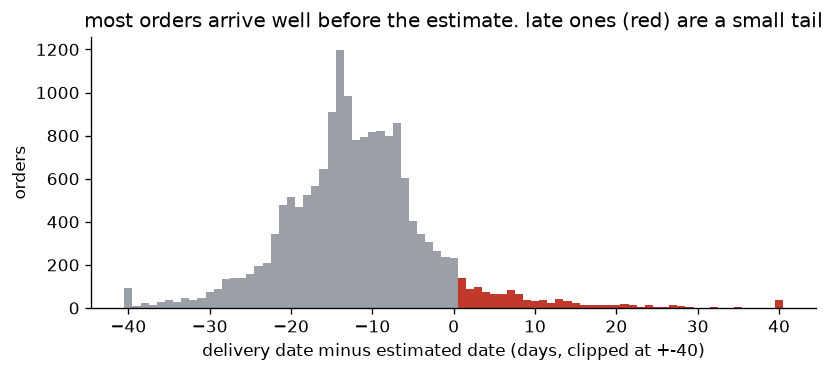

In [19]:
q1 = rate(lab)
dl = lab.days_late
late_days = dl[dl > 0]
q1_delay = late_days.describe(percentiles=[.25, .5, .75, .9]).round(1)
print(q1.round(4).to_string(index=False))
print("days late among late orders:"); print(q1_delay)
print("late by more than a week:", round((late_days > 7).mean(), 3))

counts = dl.clip(-40, 40).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(counts.index, counts.values, color=[HI if d > 0 else GREY for d in counts.index], width=1)
ax.set_xlabel("delivery date minus estimated date (days, clipped at +-40)")
ax.set_ylabel("orders")
ax.set_title("most orders arrive well before the estimate. late ones (red) are a small tail")
fig.tight_layout(); fig.savefig(OUT / "q1_days_vs_estimate.png"); plt.show()
counts.rename("orders").rename_axis("days_vs_estimate").to_csv(OUT / "q1_days_vs_estimate.csv")
q1.to_csv(OUT / "q1_late_rate.csv", index=False)
q1_delay.rename("days").to_csv(OUT / "q1_delay_among_late.csv")

### q2 - time from approval to the estimated date vs late delivery

lead time = estimated delivery date minus approval time, in days. grouped by week so each bar has enough orders to mean something.

labelled orders with no approval time (no lead time): 312
lead_week  orders  late  late_rate  ci_low  ci_high
       <7     295    48      0.163   0.125    0.209
     7-14    1949    95      0.049   0.040    0.059
    14-21    4151   292      0.070   0.063    0.079
    21-28    5718   428      0.075   0.068    0.082
    28-35    2745   177      0.064   0.056    0.074
    35-42     907    35      0.039   0.028    0.053
      42+     405     7      0.017   0.008    0.035
spearman corr lead days vs days late: -0.565


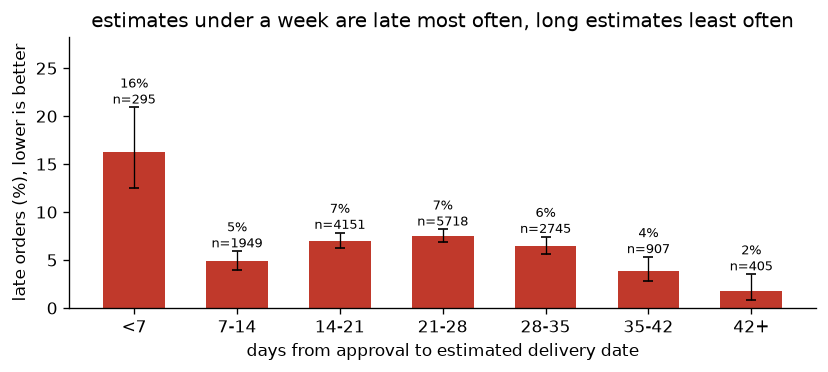

In [20]:
print("labelled orders with no approval time (no lead time):", lab.lead_days.isna().sum())
bins = [0, 7, 14, 21, 28, 35, 42, np.inf]
names = ["<7", "7-14", "14-21", "21-28", "28-35", "35-42", "42+"]
lab["lead_week"] = pd.cut(lab.lead_days, bins, labels=names, right=False)
q2 = rate(lab.dropna(subset=["lead_week"]), "lead_week")
print(q2.round(3).to_string(index=False))
print("spearman corr lead days vs days late:", round(lab[["lead_days", "days_late"]].corr("spearman").iloc[0, 1], 3))

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(q2))
ax.bar(x, q2.late_rate * 100, color=HI, width=0.6)
ax.errorbar(x, q2.late_rate * 100, yerr=[(q2.late_rate - q2.ci_low) * 100, (q2.ci_high - q2.late_rate) * 100], fmt="none", ecolor="black", lw=0.8, capsize=3)
for i, r in q2.iterrows():
    ax.text(i, r.ci_high * 100 + 0.4, f"{r.late_rate:.0%}\nn={r.orders}", ha="center", fontsize=8)
ax.set_xticks(x, q2.lead_week.astype(str))
ax.set_xlabel("days from approval to estimated delivery date")
ax.set_ylabel("late orders (%), lower is better")
ax.set_ylim(0, (q2.ci_high.max() * 100) * 1.35)
ax.set_title("estimates under a week are late most often, long estimates least often")
fig.tight_layout(); fig.savefig(OUT / "q2_late_by_lead_time.png"); plt.show()
q2.to_csv(OUT / "q2_late_by_lead_time.csv", index=False)

### q3 - late rate by customer state, and where to look first

a high rate on a handful of orders is mostly noise, and a slightly raised rate on thousands of orders is a lot of late deliveries. so states are ranked by excess late orders: late orders minus what the overall rate would predict for that many orders. that counts how many late deliveries the operations team could hope to remove by fixing that state.

labelled orders with no customer state: 951
customer_state  orders  late  late_rate  ci_low  ci_high  excess_late
            RJ    2036   235      0.115   0.102    0.130       98.254
            BA     520    61      0.117   0.092    0.148       26.075
            CE     191    35      0.183   0.135    0.244       22.172
            PE     240    37      0.154   0.114    0.205       20.881
            MA     129    23      0.178   0.122    0.253       14.336
            ES     297    30      0.101   0.072    0.141       10.052
            AL      75    14      0.187   0.115    0.289        8.963
            PA     144    16      0.111   0.070    0.173        6.328


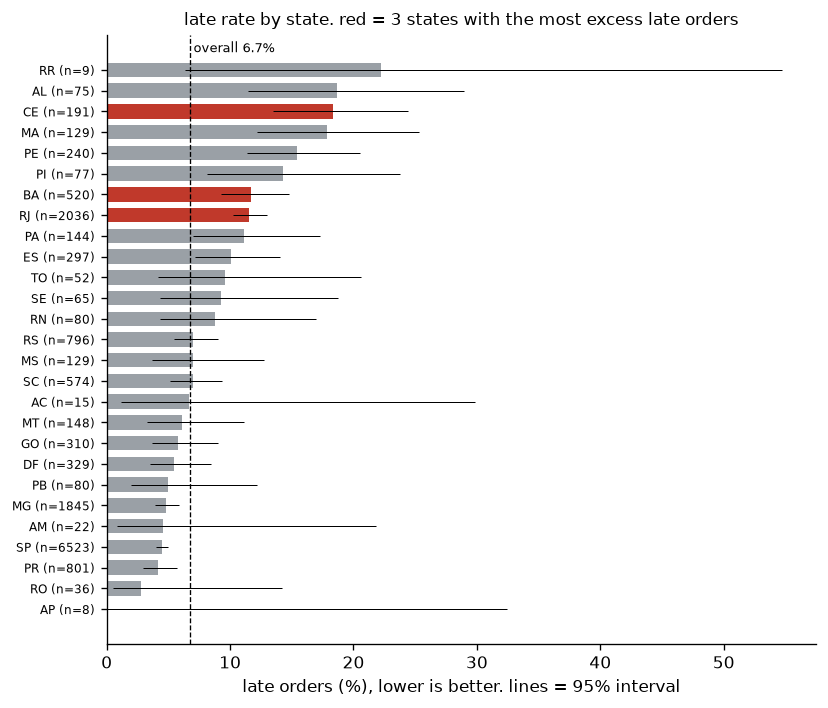

In [21]:
overall = q1.late_rate.iloc[0]
print("labelled orders with no customer state:", lab.customer_state.isna().sum())
q3 = rate(lab.dropna(subset=["customer_state"]), "customer_state")
q3["excess_late"] = q3.late - q3.orders * overall
q3 = q3.sort_values("excess_late", ascending=False).reset_index(drop=True)
print(q3.head(8).round(3).to_string(index=False))

top = set(q3.head(3).customer_state)
p = q3.sort_values("late_rate")
fig, ax = plt.subplots(figsize=(7, 6))
y = np.arange(len(p))
ax.barh(y, p.late_rate * 100, color=[HI if s in top else GREY for s in p.customer_state], height=0.7)
ax.errorbar(p.late_rate * 100, y, xerr=[(p.late_rate - p.ci_low) * 100, (p.ci_high - p.late_rate) * 100], fmt="none", ecolor="black", lw=0.6)
ax.axvline(overall * 100, color="black", ls="--", lw=0.8)
ax.text(overall * 100, len(p) - 0.3, f" overall {overall:.1%}", fontsize=8, va="bottom")
ax.set_yticks(y, [f"{s} (n={n})" for s, n in zip(p.customer_state, p.orders)], fontsize=7)
ax.set_xlabel("late orders (%), lower is better. lines = 95% interval")
ax.set_title("late rate by state. red = 3 states with the most excess late orders", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "q3_late_by_state.png"); plt.show()
q3.to_csv(OUT / "q3_late_by_state.csv", index=False)

### extra checks

three things the questions dont ask directly but the answers depend on:
- is lateness spread evenly over time, or bunched in some months
- is the q2 lead time effect really distance or season in disguise. compare short and long estimates inside the same state and the same purchase month
- how far could the cancelled orders move the late rate. we cant label them, but we can bound them

  month  orders  late  late_rate  ci_low  ci_high
2018-03    1183   216      0.183   0.162    0.206
2018-02    1117   158      0.141   0.122    0.163
2017-11    1210   145      0.120   0.103    0.139
2017-12     925    72      0.078   0.062    0.097


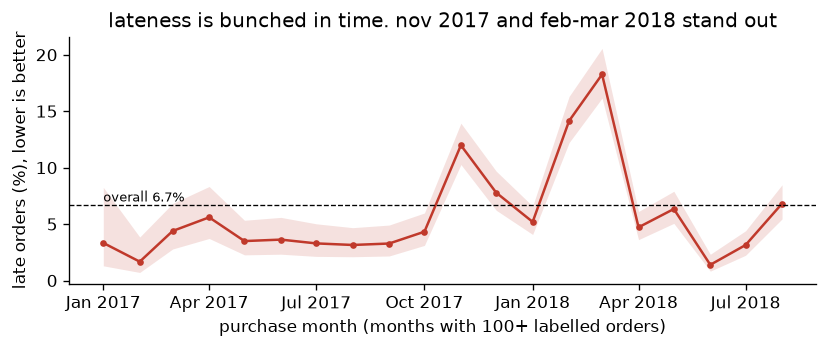

short estimates placed in the 3 spike months: 0 of 284
short estimate (<7 days)                   0.163
longer estimate, same state and month      0.042
short orders compared                    276.000
dtype: float64
labelled orders only                             0.0672
if no cancelled order would have been late       0.0635
if every cancelled order would have been late    0.1177
dtype: float64


In [22]:
lab["month"] = lab.order_purchase_timestamp.dt.to_period("M")
q1m = rate(lab, "month")
q1m = q1m[q1m.orders >= 100]  # the first months of 2016 have a handful of orders
print(q1m.assign(month=q1m.month.astype(str)).sort_values("late_rate", ascending=False).head(4).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
x = q1m.month.dt.to_timestamp()
ax.plot(x, q1m.late_rate * 100, color=HI, marker="o", ms=3)
ax.fill_between(x, q1m.ci_low * 100, q1m.ci_high * 100, color=HI, alpha=0.15, lw=0)
ax.axhline(overall * 100, color="black", ls="--", lw=0.8)
ax.set_ylabel("late orders (%), lower is better")
ax.text(x.iloc[0], overall * 100, f"overall {overall:.1%}", fontsize=8, va="bottom")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_xlabel("purchase month (months with 100+ labelled orders)")
ax.set_title("lateness is bunched in time. nov 2017 and feb-mar 2018 stand out")
fig.tight_layout(); fig.savefig(OUT / "q1_late_by_month.png"); plt.show()
q1m.assign(month=q1m.month.astype(str)).to_csv(OUT / "q1_late_by_month.csv", index=False)

# q2 inside the same state and month: weight each stratum by its number of short orders
s = lab.dropna(subset=["lead_days", "customer_state"]).assign(short=lambda d: d.lead_days < 7)
spike = s.month.astype(str).isin(["2017-11", "2018-02", "2018-03"])
print("short estimates placed in the 3 spike months:", int((s.short & spike).sum()), "of", int(s.short.sum()))
g = s.groupby(["customer_state", "month", "short"], observed=True).late.agg(["size", "mean"]).unstack("short").dropna()
w = g[("size", True)]
q2s = pd.Series({"short estimate (<7 days)": (g[("mean", True)] * w).sum() / w.sum(),
                 "longer estimate, same state and month": (g[("mean", False)] * w).sum() / w.sum(),
                 "short orders compared": w.sum()}).round(3)
print(q2s)
q2s.rename("value").to_csv(OUT / "q2_within_state_month.csv")

# bounds: 944 cancelled or unavailable orders, either none or all of them would have been late
k, n, c = lab.late.sum(), len(lab), (o.unlabelled_reason == "cancelled or unavailable").sum()
bounds = pd.Series({"labelled orders only": k / n, "if no cancelled order would have been late": k / (n + c),
                    "if every cancelled order would have been late": (k + c) / (n + c)}).round(4)
print(bounds)
bounds.rename("late_rate").to_csv(OUT / "late_rate_bounds.csv")

### how much do the answers depend on which records are included

each row changes one choice and recomputes the headline numbers:
- `baseline` the labels from step 2
- `+ not_reported` gives a label to `not_reported` orders that have usable dates (status unknown, dates look fine)
- `+ 7 day shift undone` moves the delivery dates that are exactly 7 days before approval forward by 7 days and labels those orders
- `no recovered states` drops states recovered from the zip (q3 only)
- `no missing prices` only orders where every item price and freight is known

In [23]:
def variant(df):
    q2v = rate(df.dropna(subset=["lead_week"]), "lead_week").set_index("lead_week").late_rate
    q3v = rate(df.dropna(subset=["customer_state"]), "customer_state")
    q3v["excess_late"] = q3v.late - q3v.orders * df.late.mean()
    r = rate(df).iloc[0]
    return {"orders": len(df), "late_rate": round(r.late_rate, 4), "ci": f"{r.ci_low:.3f}-{r.ci_high:.3f}",
            "median_days_late": df.days_late[df.days_late > 0].median(),
            "late_rate_lead_<7": round(q2v.get("<7"), 3), "late_rate_lead_28-35": round(q2v.get("28-35"), 3),
            "top3_states_by_excess": " ".join(q3v.nlargest(3, "excess_late").customer_state)}

def relabel(df, dl):
    df = df.copy()
    df["days_late"] = (dl.dt.normalize() - df.order_estimated_delivery_date.dt.normalize()).dt.days
    df["late"] = (df.days_late > 0).astype(int)
    df["lead_days"] = (df.order_estimated_delivery_date - df.order_approved_at).dt.total_seconds() / 86400
    df["lead_week"] = pd.cut(df.lead_days, bins, labels=names, right=False)
    return df[df.order_estimated_delivery_date.notna()]

dlv, apv = o.order_delivered_customer_date, o.order_approved_at
nr = o[(o.unlabelled_reason == "status unknown") & dlv.notna() & ~(dlv < apv) & ~(dlv < o.order_purchase_timestamp)]
shifted = o[(o.unlabelled_reason == "delivery dated before purchase or approval") & (o.order_status == "delivered") & ((apv - dlv) == pd.Timedelta(days=7))]
sens = pd.DataFrame({
    "baseline": variant(lab),
    "+ not_reported": variant(pd.concat([lab, relabel(nr, nr.order_delivered_customer_date)])),
    "+ 7 day shift undone": variant(pd.concat([lab, relabel(shifted, shifted.order_delivered_customer_date + pd.Timedelta(days=7))])),
    "no recovered states": variant(lab[~lab.customer_state_recovered]),
    "no missing prices": variant(lab[(lab.n_price_null == 0) & (lab.n_freight_null == 0) & (lab.n_items > 0)]),
}).T
sens.to_csv(OUT / "sensitivity.csv")
sens

,orders,late_rate,ci,median_days_late,late_rate_lead_<7,late_rate_lead_28-35,top3_states_by_excess
baseline,16482,0.0672,0.063-0.071,7.0,0.163,0.064,RJ BA CE
+ not_reported,17262,0.0679,0.064-0.072,7.0,0.165,0.067,RJ BA CE
+ 7 day shift undone,17264,0.0641,0.061-0.068,7.0,0.161,0.061,RJ BA CE
no recovered states,15757,0.0672,0.063-0.071,7.0,0.166,0.065,RJ BA CE
no missing prices,15775,0.0673,0.063-0.071,7.0,0.171,0.064,RJ BA CE


### answers

**q1.** about 1 in 15 labelled orders arrives late (6.7%, 95% interval 6.3-7.1%). when an order is late its usually by about a week (median 7 days, middle half 3-13 days) but the tail is long, about 1 in 8 is 3+ weeks late. most orders arrive well before the estimate, the typical one about 12 days early. so estimates are padded and late deliveries are the exception. but they are not spread evenly in time. orders bought in march 2018 were late 18% of the time, february 2018 14% and november 2017 (black friday) 12%, against 5-7% in a normal month. the data doesnt say why.

**q2.** estimates under a week are late about 16% of the time, more than double the overall rate. from 1 to 5 weeks the rate sits around 5-8% and it drops to around 2-4% beyond 5 weeks. so short estimates are the risky ones, long ones have slack built in. the obvious worry is that this is really state or season. it isnt explained by either. none of the short estimates fall in the 3 spike months, and comparing short and longer estimates inside the same state and the same purchase month gives 16.3% vs 4.2% late. it is still an association, other things (seller, product, carrier) could sit behind it, so it doesnt say that giving a longer estimate would make deliveries arrive sooner. it does say the estimate itself carries useful risk information at approval time.

**q3.** rio de janeiro (RJ) first. its rate (11.5%) is less extreme than some north east states but it has 2000+ orders, so it has by far the most excess late orders (about 100 more than the overall rate would predict) and a tight interval. after that bahia (BA) and ceara (CE). states like RR or AP look extreme but rest on fewer than 10 orders, the intervals cover almost anything. the south east and south (SP, PR, MG) are below average.

**data quality and confidence.** the headline numbers barely move when the cleaning choices change (table above). adding the `not_reported` orders or undoing the 7 day shift moves the late rate by less than half a point and the top 3 states stay RJ, BA, CE in every version. the main gap is coverage. about 1 in 6 orders (18%) has no label, and 951 labelled orders have no state (mostly the orders with no customer row). if those orders were systematically different (say cancellations hiding late deliveries) the rates would be biased. the data cant check that, but it can bound it. if none of the 944 cancelled or unavailable orders would have been late the rate is 6.4%, if every one would have been late it is 11.8%. the truth sits in between and the data cant narrow it. 743 of the 944 had already been handed to the carrier, so many were cancelled after shipping, when lateness could have played a part. so the 6.7% is best read as a lower end. this is also one modified extract over 2016-2018, so the operations team should treat RJ, BA, CE and the under-a-week estimates as where to look first, not as proven causes.

In [24]:
done()

{'step': '03_eda',
 'seconds': 0.48,
 'rss_start_MB': 270.34,
 'rss_peak_MB': 322.19,
 'rss_peak_above_start_MB': 51.86,
 'saved_MB': {'late_rate_bounds.csv': 0.0,
  'q1_days_vs_estimate.csv': 0.0,
  'q1_days_vs_estimate.png': 0.02,
  'q1_delay_among_late.csv': 0.0,
  'q1_late_by_month.csv': 0.0,
  'q1_late_by_month.png': 0.05,
  'q1_late_rate.csv': 0.0,
  'q2_late_by_lead_time.csv': 0.0,
  'q2_late_by_lead_time.png': 0.03,
  'q2_within_state_month.csv': 0.0,
  'q3_late_by_state.csv': 0.0,
  'q3_late_by_state.png': 0.06,
  'sensitivity.csv': 0.0}}

## step 4 - feature engineering

in: `data/02_clean/orders_clean.parquet`, `data/02_clean/items_clean.parquet`

out, in `data/04_features/`:
- `features.parquet` one row per labelled order, numbers only, no ids, no label
- `ids_labels.parquet` `order_id` and `delivered_after_estimate`, same row order as `features.parquet`
- `feature_descriptions.csv` what each feature means and which raw columns it comes from
- `leakage_check.csv` how well each feature on its own separates late from on time

rows: the 16,482 labelled orders. unlabelled orders have no reliable label, so a model cant learn from them.

only information known at approval (brief): basket, prices, freight, estimated date, customer location, product and seller attributes, plus the purchase and approval times themselves. never payments, status, carrier or delivery dates, reviews or `shipping_limit_date`.

representation:
- numbers stay numbers. sums and counts per order since the label is per order
- missing stays missing (NaN) with a `_missing` flag next to it. filling with a median here would use every order, including the ones a model is later tested on, so imputing is left to the model fitting step
- states and categories are one hot. 27 states is small enough. categories keep the 15 most common plus `other` and `missing`, rare ones would be columns with a handful of ones
- month, weekday and hour are cyclical (sin, cos) so december sits next to january and 23h next to 0h
- no year. a model is used on future orders, and a year it never saw tells it nothing

estimate before running: under a second. memory above start about 30-60 MB (orders 6 MB + items 7 MB in memory, features 16k rows x ~70 columns x 8 bytes = ~9 MB, a couple of pandas copies on top). saved under 2 MB.

In [25]:
OUT, done = track("04_features")
o = pd.read_parquet(ROOT / "data" / "02_clean" / "orders_clean.parquet")
it = pd.read_parquet(ROOT / "data" / "02_clean" / "items_clean.parquet")
lab = o[o.unlabelled_reason.isna()].set_index("order_id")
y, days_late = lab.delivered_after_estimate.astype(int), lab.days_late

# columns not known at approval are dropped before any feature is built, so using one by mistake fails loudly
FORBIDDEN = ["payment", "order_status", "carrier", "delivered_customer", "review", "shipping_limit"]
gone = [c for c in o.columns if any(w in c for w in FORBIDDEN)] + ["delivered_after_estimate", "days_late", "unlabelled_reason"]
lab = lab.drop(columns=gone)
it = it.drop(columns=["shipping_limit_date"])
it = it[it.order_id.isin(lab.index)].join(lab.customer_state, on="order_id")
print(len(lab), "labelled orders,", len(it), "of their items. dropped:", gone)

16482 labelled orders, 18814 of their items. dropped: ['order_status', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'n_payments', 'payment_sum_centavos', 'n_payment_null', 'n_reviews', 'delivered_after_estimate', 'days_late', 'unlabelled_reason']


In [26]:
days = lambda td: td.dt.total_seconds() / 86400
f = pd.DataFrame(index=lab.index)
ap, pu, est = lab.order_approved_at, lab.order_purchase_timestamp, lab.order_estimated_delivery_date

# timing
f["lead_days"] = days(est - ap)
f["est_days_from_purchase"] = days(est - pu)
f["approval_hours"] = days(ap - pu) * 24
for name, x, period in [("month", pu.dt.month - 1, 12), ("weekday", pu.dt.dayofweek, 7), ("hour", pu.dt.hour, 24)]:
    f[f"purchase_{name}_sin"] = np.sin(2 * np.pi * x / period)
    f[f"purchase_{name}_cos"] = np.cos(2 * np.pi * x / period)

# basket. a sum with a missing price would be too low, so it becomes missing
f["n_items"], f["n_products"], f["n_sellers"] = lab.n_items, lab.n_products, lab.n_sellers
f["price_sum"] = lab.price_sum.where(lab.n_price_null == 0)
f["freight_sum"] = lab.freight_sum.where(lab.n_freight_null == 0)
f["freight_share"] = f.freight_sum / (f.price_sum + f.freight_sum)

# product and seller attributes, item rows to one row per order
it["volume_cm3"] = it.product_length_cm * it.product_height_cm * it.product_width_cm
it["same_state"] = (it.seller_state == it.customer_state).astype("float64")
g = it.groupby("order_id")
any_na = lambda c: it[c].isna().groupby(it.order_id).any()
f["weight_g_sum"] = g.product_weight_g.sum().where(~any_na("product_weight_g"))
f["volume_cm3_sum"] = g.volume_cm3.sum().where(~any_na("volume_cm3"))
f["photos_mean"] = g.product_photos_qty.mean()
f["n_categories"] = g.product_category_name.nunique()
f["n_seller_states"] = g.seller_state.nunique()
f["share_items_same_state"] = g.same_state.mean()  # seller and customer in the same state

# category of the most expensive item in the order
main = it.sort_values("price", ascending=False).drop_duplicates("order_id").set_index("order_id")
cat = main.product_category_name_english.fillna(main.product_category_name).reindex(lab.index)
top = cat.value_counts().head(15).index
cat = cat.where(cat.isin(top) | cat.isna(), "other").fillna("missing")
state = lab.customer_state.fillna("missing")

f = f.astype("float64")
for c in ["lead_days", "est_days_from_purchase", "approval_hours", "price_sum", "freight_sum", "weight_g_sum", "volume_cm3_sum", "photos_mean", "share_items_same_state"]:
    f[f"{c}_missing"] = f[c].isna().astype("float64")
f = f.join(pd.get_dummies(state, prefix="state", dtype="float64")).join(pd.get_dummies(cat, prefix="cat", dtype="float64"))
f.columns = f.columns.str.replace(" ", "_")
print(f.shape, "| all numeric:", all(pd.api.types.is_float_dtype(t) for t in f.dtypes))
f.describe().T[["count", "mean", "min", "max"]].round(2).head(25)

(16482, 75) | all numeric: True


,count,mean,min,max
lead_days,16170.0,23.27,0.86,101.00
est_days_from_purchase,16155.0,23.69,2.05,101.01
approval_hours,15843.0,10.05,0.00,741.44
purchase_month_sin,16155.0,0.13,-1.00,1.00
purchase_month_cos,16155.0,-0.06,-1.00,1.00
purchase_weekday_sin,16155.0,0.07,-0.97,0.97
purchase_weekday_cos,16155.0,0.01,-0.90,1.00
purchase_hour_sin,16155.0,-0.33,-1.00,1.00
purchase_hour_cos,16155.0,-0.22,-1.00,1.00
n_items,16482.0,1.14,1.00,21.00


### leakage check

two parts.

1. every feature is built from an allowed column only. the descriptions table lists the source columns of each feature and the forbidden ones are checked against it.
2. each feature on its own is scored against the label with the area under the roc curve (auc). 0.5 = no signal, 1 or 0 = separates late from on time perfectly. a single feature near 1 or 0 almost always means it secretly contains the outcome. as a positive control `days_late` (the delivery outcome itself, never a feature) is scored too. it should come out near 1, which shows the check can catch a leak.

In [27]:
DESC = {
    "lead_days": ("days from approval to the estimated delivery date", "order_approved_at, order_estimated_delivery_date"),
    "est_days_from_purchase": ("days from purchase to the estimated delivery date. known even when approval time is missing", "order_purchase_timestamp, order_estimated_delivery_date"),
    "approval_hours": ("hours from purchase to approval", "order_purchase_timestamp, order_approved_at"),
    "purchase_month": ("purchase month on a circle (sin, cos)", "order_purchase_timestamp"),
    "purchase_weekday": ("purchase weekday on a circle (sin, cos)", "order_purchase_timestamp"),
    "purchase_hour": ("purchase hour on a circle (sin, cos)", "order_purchase_timestamp"),
    "n_items": ("number of items in the order", "order_items"),
    "n_products": ("number of different products", "order_items.product_id"),
    "n_sellers": ("number of different sellers", "order_items.seller_id"),
    "price_sum": ("total item price in BRL, missing if any item price is missing", "order_items.price"),
    "freight_sum": ("total freight in BRL, missing if any freight is missing", "order_items.freight_value"),
    "freight_share": ("freight / (price + freight)", "order_items.price, order_items.freight_value"),
    "weight_g_sum": ("total product weight in grams, missing if any item weight is missing", "products.product_weight_g"),
    "volume_cm3_sum": ("total product volume (length x height x width) in cm3", "products.product_*_cm"),
    "photos_mean": ("mean number of product photos", "products.product_photos_qty"),
    "n_categories": ("number of different product categories", "products.product_category_name"),
    "n_seller_states": ("number of different seller states", "sellers.seller_state"),
    "share_items_same_state": ("share of items whose seller is in the customers state", "sellers.seller_state, customers.customer_state"),
    "state": ("one hot customer state, `state_missing` when unknown", "customers.customer_state"),
    "cat": ("one hot category of the most expensive item, top 15 + other + missing", "products.product_category_name, category_translation"),
}
def describe(c):
    base = c.removesuffix("_missing").removesuffix("_sin").removesuffix("_cos")
    key = base if base in DESC else c.split("_")[0]
    meaning, source = DESC[key]
    if c.endswith("_missing"):
        meaning = f"1 if {base} is missing"
    elif key in ("state", "cat"):
        meaning = f"1 if {c.split('_', 1)[1]}. {meaning}"
    return meaning, source

desc = pd.DataFrame([(c, *describe(c)) for c in f.columns], columns=["feature", "meaning", "source_columns"])
print("features built from a forbidden column:", desc[desc.source_columns.str.contains("|".join(FORBIDDEN))].feature.tolist())

def auc(x):
    m = x.notna()
    r, pos = x[m].rank(), y[m] == 1
    n1, n0 = pos.sum(), (~pos).sum()
    return (r[pos].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

leak = pd.DataFrame({"auc": f.apply(auc), "non_missing": f.notna().sum()})
leak.loc["days_late (control, not a feature)"] = [auc(days_late.astype("float64")), days_late.notna().sum()]
leak["gap_from_half"] = (leak.auc - 0.5).abs()
leak = leak.sort_values("gap_from_half", ascending=False).round(3)
print("features with auc above 0.8 or below 0.2:", leak.drop("days_late (control, not a feature)").query("gap_from_half > 0.3").index.tolist())
leak.head(8)

features built from a forbidden column: []


features with auc above 0.8 or below 0.2: []


,auc,non_missing,gap_from_half
"days_late (control, not a feature)",1.000,16482.0,0.500
purchase_month_cos,0.608,16155.0,0.108
state_SP,0.428,16482.0,0.072
share_items_same_state,0.436,14781.0,0.064
freight_sum,0.559,16150.0,0.059
state_RJ,0.548,16482.0,0.048
weight_g_sum,0.535,15019.0,0.035
price_sum,0.532,16103.0,0.032


In [28]:
f.reset_index(drop=True).to_parquet(OUT / "features.parquet")
ids = y.rename("delivered_after_estimate").reset_index()
assert (ids.order_id == f.index).all() and ids.order_id.is_unique and len(ids) == len(lab)
ids.to_parquet(OUT / "ids_labels.parquet", index=False)
desc.to_csv(OUT / "feature_descriptions.csv", index=False)
leak.to_csv(OUT / "leakage_check.csv")
done(in_memory_MB={"orders": mb(o.memory_usage(deep=True).sum()), "items": mb(it.memory_usage(deep=True).sum()), "features": mb(f.memory_usage(deep=True).sum())})

{'step': '04_features',
 'seconds': 0.2,
 'rss_start_MB': 322.17,
 'rss_peak_MB': 368.75,
 'rss_peak_above_start_MB': 46.58,
 'saved_MB': {'feature_descriptions.csv': 0.01,
  'features.parquet': 0.78,
  'ids_labels.parquet': 0.57,
  'leakage_check.csv': 0.0},
 'in_memory_MB': {'orders': np.float64(6.56),
  'items': np.float64(6.77),
  'features': np.float64(11.08)}}

## step 5 - resources and environment

one command rebuilds everything: `uv run python run.py`. it checks the supplied files against `supplied.sha256`, rebuilds the db from `raw.sql` with the supplied `setup_db.py`, runs this notebook top to bottom and writes `data/manifest.sha256` with a hash of every output. two runs giving the same manifest show the outputs are reproduced byte for byte (timing files excluded, timings always differ).

measurement scope:
- runtime: wall clock of the step inside this kernel
- memory: rss of this kernel sampled every 10 ms during the step. `rss_peak_above_start` is what the step itself added, `rss_start` includes python, pandas and data left from earlier steps
- saved storage: size on disk of the step's output files
- temporary storage: files that exist only during the step

estimate rule used for every step: peak memory above start ~ 2-3x the in-memory size of the data the step holds (pandas makes a copy or two while filtering and joining). the step 1 sql vs pandas comparison and step 4 also had a written estimate before running.

In [29]:
import platform
steps = sorted(ROOT.glob("data/0*/resources.json"))
res = pd.DataFrame([json.loads(p.read_text()) for p in steps]).set_index("step")
res["saved_MB_total"] = res.saved_MB.apply(lambda d: round(sum(d.values()), 2))
res["data_in_memory_MB"] = res.in_memory_MB.apply(lambda d: round(sum(d.values()), 2) if isinstance(d, dict) else np.nan)
res["estimate_peak_above_start_MB"] = res.data_in_memory_MB.apply(lambda m: f"{2 * m:.0f}-{3 * m:.0f}" if m == m else "")
tmp = pd.read_csv(ROOT / "data" / "01_load" / "load_comparison_raw.csv").db_MB.max()
res["temporary_MB"] = pd.Series({"01_load": tmp})
summary = res[["seconds", "rss_start_MB", "rss_peak_MB", "rss_peak_above_start_MB", "data_in_memory_MB", "estimate_peak_above_start_MB", "saved_MB_total", "temporary_MB"]]
summary.loc["00_setup_db (run.py)", "saved_MB_total"] = mb(DB.stat().st_size)
summary.to_csv(ROOT / "data" / "resources_summary.csv")
summary

,seconds,rss_start_MB,rss_peak_MB,rss_peak_above_start_MB,data_in_memory_MB,estimate_peak_above_start_MB,saved_MB_total,temporary_MB
step,,,,,,,,
01_load,0.26,130.76,216.47,85.70,12.89,26-39,5.15,240.39
02_clean,0.27,146.33,244.04,97.71,17.83,36-53,6.55,NaN
03_eda,0.48,270.34,322.19,51.86,NaN,,0.16,NaN
04_features,0.20,322.17,368.75,46.58,24.41,49-73,1.36,NaN
00_setup_db (run.py),NaN,NaN,NaN,NaN,NaN,NaN,24.36,NaN


step 3 holds the cleaned orders (~6 MB) plus a few grouped tables, it has no `in_memory_MB` entry. step 1's `temporary_MB` is the 10x copy of the db used by the scaling comparison, deleted straight after. that comparison runs after step 1's `done()` so it is not inside step 1's numbers, its own peaks are in `load_comparison.csv`.

estimated vs measured. step 4 landed inside its estimate (58 MB measured vs 49-73). steps 1 and 2 used about 2x more than the rule said (85 vs 26-39, 96 vs 36-53 MB). the rule only counts the dataframes. the likely gap (not measured separately) is the arrow buffers adbc hands over before pandas wraps them, and rss keeps memory pandas has freed but the allocator hasnt handed back to the os. so for steps that read from the db or copy many columns, 4-6x the data size is the better rule. every step is far below what the machine has (38 GB), runtime is under half a second per step, and the 10x scaling test in step 1 shows the loading step stays small as the data grows.

In [30]:
from importlib.metadata import version
env = {"python": platform.python_version(), "os": platform.platform(), "machine": platform.machine(),
       "cpu_count": psutil.cpu_count(), "ram_GB": round(psutil.virtual_memory().total / 1e9, 1),
       **{p: version(p) for p in ["pandas", "numpy", "pyarrow", "adbc-driver-sqlite", "matplotlib", "psutil"]}}
(ROOT / "data" / "environment.json").write_text(json.dumps(env, indent=1))
pd.Series(env)

python                                   3.12.12
os                    macOS-27.0-arm64-arm-64bit
machine                                    arm64
cpu_count                                     14
ram_GB                                      38.7
pandas                                     3.0.6
numpy                                      2.5.4
pyarrow                                   26.0.0
adbc-driver-sqlite                        1.12.0
matplotlib                                3.11.2
psutil                                     7.2.2
dtype: object